<a href="https://colab.research.google.com/github/quinsan7/inteligencia_artificial/blob/main/Atividade_Entrega_FishMorphDB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bloco 1 — Importação das bibliotecas

## Explicação:
importa as bibliotecas utilizadas para manipular dados, gerar gráficos, preparar os dados e treinar e avaliar o modelo SVM.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

#Bloco 2 — Carregamento e visualização inicial dos dados

##Explicação:
carrega o arquivo CSV, mostra a quantidade de linhas e colunas e exibe as primeiras linhas do conjunto de dados.

In [ ]:
df = pd.read_csv('/content/FISHMORPH_Family_Dataset.csv')
print(df.shape)
df.head()

(8342, 11)


,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt,Family
0,130.0,4.579113,0.622642,0.375019,0.622642,0.868659,0.484981,0.273585,0.144108,3.348991,Cyprinidae
1,11.5,2.796068,0.650700,0.353780,0.509800,0.411157,0.722461,0.330169,0.221095,2.525592,Cichlidae
2,6.6,4.564329,0.518187,0.312002,0.203985,0.413221,0.591495,0.105517,0.188193,2.104580,Cyprinidae
3,10.9,4.390422,0.548247,0.244804,0.168959,0.324728,0.642991,0.097450,0.193049,1.787062,Cyprinidae
4,18.9,4.410271,0.542353,0.292058,0.183790,0.398567,0.685672,0.087643,0.170648,2.968906,Cyprinidae


#Bloco 3 — Análise exploratória dos dados

##Explicação:
verifica os tipos de dados, apresenta estatísticas descritivas, identifica valores ausentes e conta os registros duplicados.

In [ ]:
df.info()
print(df.describe())
print("\nNulos por coluna:\n", df.isnull().sum())
print("Duplicatas:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8342 entries, 0 to 8341
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   MBl     8342 non-null   float64
 1   BEl     8342 non-null   float64
 2   VEp     8342 non-null   float64
 3   REs     8342 non-null   float64
 4   OGp     8342 non-null   float64
 5   RMl     8342 non-null   float64
 6   BLs     8342 non-null   float64
 7   PFv     8342 non-null   float64
 8   PFs     8342 non-null   float64
 9   CPt     8342 non-null   float64
 10  Family  8342 non-null   object 
dtypes: float64(10), object(1)
memory usage: 717.0+ KB
               MBl          BEl          VEp          REs          OGp  \
count  8342.000000  8342.000000  8342.000000  8342.000000  8342.000000   
mean     22.004517     4.452438     0.549087     0.391665     0.381768   
std      33.612007     2.338235     0.094883     0.132814     0.194352   
min       1.200000     1.033084     0.159248     0.000000    

#Bloco 4 — Limpeza dos dados

##Explicação:
remove registros duplicados e linhas com valores ausentes e reorganiza os índices do DataFrame.

In [ ]:
df = df.drop_duplicates().dropna().reset_index(drop=True)
print("Shape após limpeza:", df.shape)

Shape após limpeza: (8341, 11)


#Bloco 5 — Separação das variáveis preditoras e da variável-alvo

##Explicação:
separa as características numéricas dos peixes (X) da categoria que o modelo deverá prever (y).

In [ ]:
target = df.select_dtypes(exclude=[np.number]).columns[-1]
X = df.select_dtypes(include=[np.number])
y = df[target].astype(str)

#Bloco 6 — Seleção das categorias válidas

##Explicação:
mantém apenas as famílias de peixes com pelo menos cinco registros, reduzindo a quantidade de classes com poucos exemplos.

In [ ]:
validas = y.value_counts()[lambda s: s >= 5].index
mask = y.isin(validas)
X, y = X[mask], y[mask]
print("Target:", target, "| Classes:", y.nunique())

Target: Family | Classes: 118


#Bloco 7 — Distribuição das categorias

##Explicação:
gera um gráfico de barras com as 30 famílias de peixes mais frequentes, permitindo visualizar a distribuição das categorias.

/tmp/ipykernel_557/2153780357.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dist.values, y=dist.index, palette="viridis")


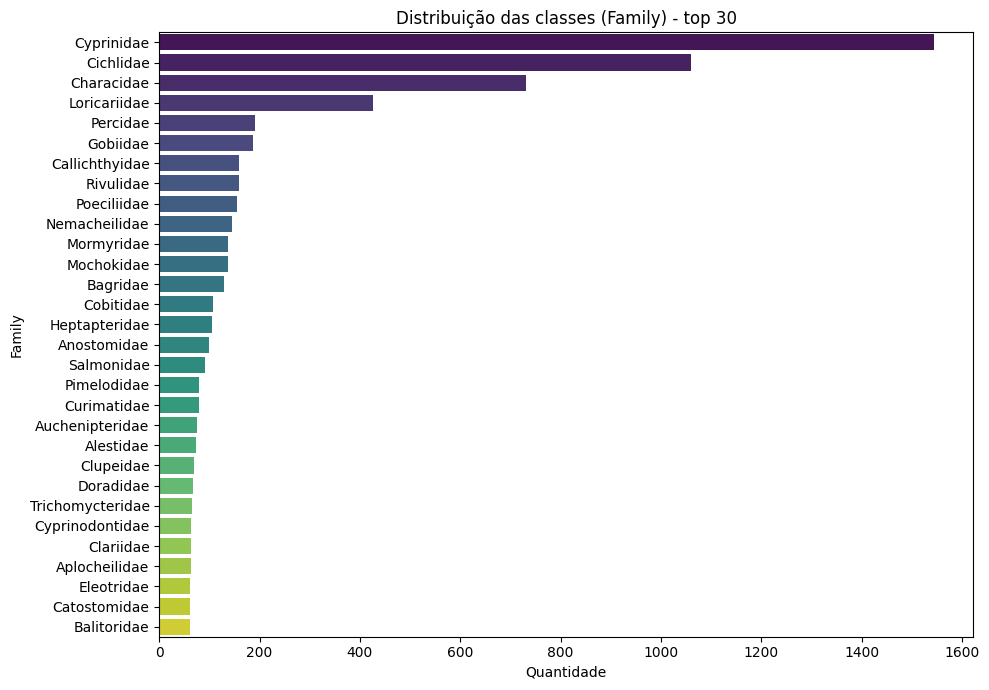

In [ ]:
dist = y.value_counts().head(30)
plt.figure(figsize=(10, 7))
sns.barplot(x=dist.values, y=dist.index, palette="viridis")
plt.title(f"Distribuição das classes ({target}) - top 30")
plt.xlabel("Quantidade")
plt.tight_layout()
plt.show()

#Bloco 8 — Divisão dos dados em treino e teste

#Explicação:
separa 80% dos dados para treinamento e 20% para teste. A estratificação procura preservar a proporção das famílias em cada conjunto.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

#Bloco 9 — Criação do pipeline do modelo SVM

##Explicação:
cria um fluxo de processamento que padroniza as características numéricas e depois aplica o algoritmo SVM para classificação.

In [ ]:
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])


#Bloco 10 — Definição dos hiperparâmetros do Grid Search

##Explicação:
define quatro kernels, quatro valores de C e quatro valores de gamma. O Grid Search testará as 64 combinações possíveis.

In [ ]:
param_grid = {
    "svm__kernel": ["linear", "poly", "rbf", "sigmoid"],
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [0.001, 0.01, 0.1, 1],
}

#Bloco 11 — Treinamento e otimização com Grid Search e Cross Validation

##Explicação:
testa as combinações de hiperparâmetros utilizando validação cruzada com três partes e seleciona a configuração com melhor acurácia média.

In [ ]:
grid = GridSearchCV(pipe, param_grid, cv=3, scoring="accuracy", n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

Fitting 3 folds for each of 64 candidates, totalling 192 fits


GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('svm', SVC())]),
             n_jobs=-1,
             param_grid={'svm__C': [0.1, 1, 10, 100],
                         'svm__gamma': [0.001, 0.01, 0.1, 1],
                         'svm__kernel': ['linear', 'poly', 'rbf', 'sigmoid']},
             scoring='accuracy', verbose=1)

#Bloco 12 — Avaliação do modelo e cálculo da acurácia

##Explicação:
utiliza o melhor modelo encontrado para prever as famílias dos peixes no conjunto de teste e calcula a proporção de previsões corretas. Também exibe os melhores parâmetros.

In [ ]:
y_pred = grid.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print("\nModelo: SVM (SVC)")
print("Melhores parâmetros:", {k.replace("svm__", ""): v for k, v in grid.best_params_.items()})
print(f"Acurácia: {acc:.4f} ({acc*100:.2f}%)")


Modelo: SVM (SVC)
Melhores parâmetros: {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}
Acurácia: 0.6697 (66.97%)


#Bloco 13 — Preparação das classes para a matriz de confusão

##Explicação:
organiza os nomes das famílias de peixes em ordem alfabética para utilizá-los nos eixos da matriz de confusão.

In [ ]:
classes = np.array(sorted(y.unique()))

#Bloco 14 — Geração da matriz de confusão

##Explicação:
compara as famílias reais com as previstas pelo modelo e gera um mapa de calor para visualizar os acertos e erros. Quando existem mais de 35 classes, o código seleciona as 20 famílias mais frequentes entre os dados de teste para exibição.

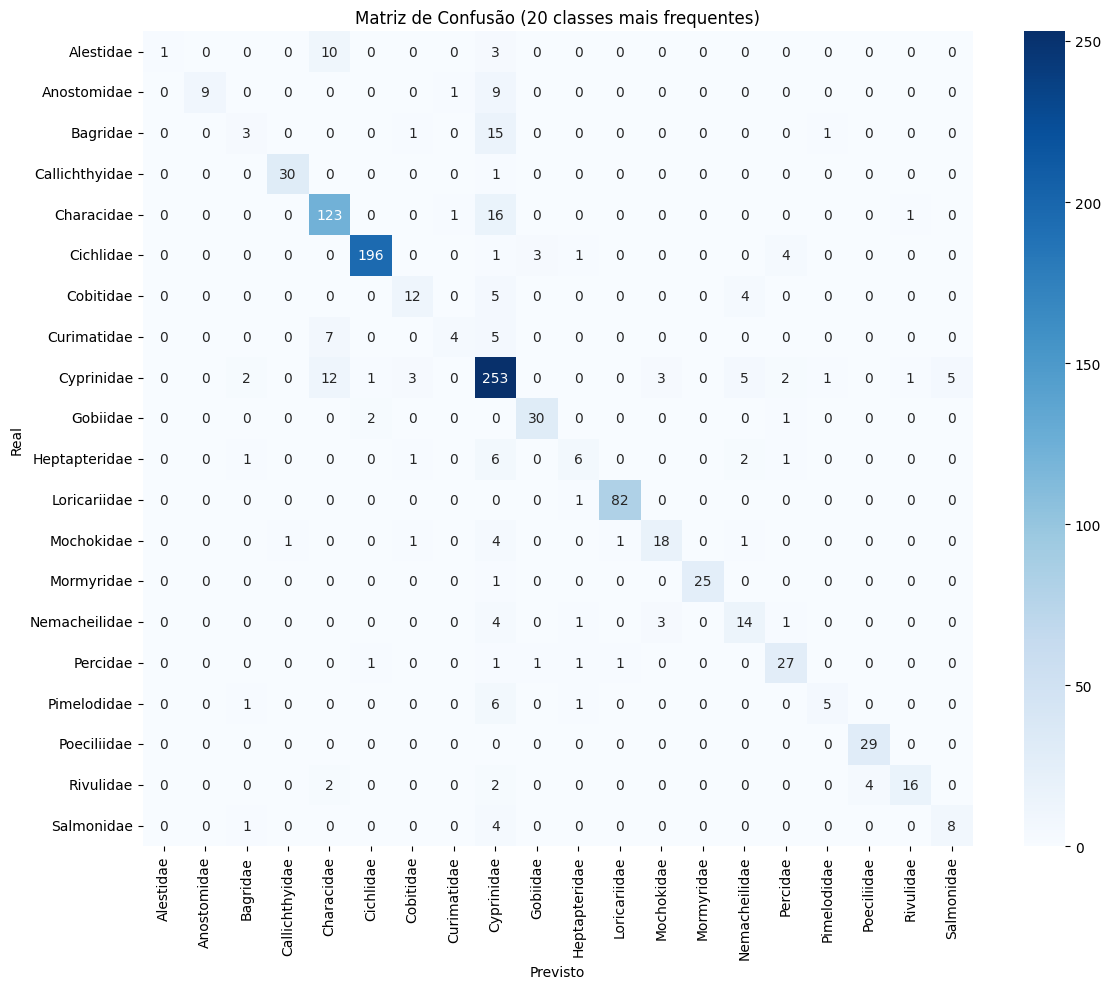

In [ ]:
if len(classes) > 35:
    top = y_test.value_counts().index[:20]
    classes = np.array(sorted(top))
    mask_t = y_test.isin(classes).values
    cm = confusion_matrix(y_test[mask_t], y_pred[mask_t], labels=classes)
    titulo = "Matriz de Confusão (20 classes mais frequentes)"
else:
    cm = confusion_matrix(y_test, y_pred, labels=classes)
    titulo = "Matriz de Confusão"

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=len(classes) <= 25, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.title(titulo)
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.tight_layout()
plt.show()

# Conclusão

O modelo SVM obteve uma acurácia de **66,97%**, utilizando o kernel RBF, com os parâmetros C = 10 e gamma = 0.1. A distribuição das categorias permitiu visualizar a frequência das famílias de peixes, enquanto a divisão dos dados em 80% para treino e 20% para teste possibilitou avaliar o modelo. O Cross Validation, com 3 partes, e o Grid Search foram utilizados para encontrar a melhor combinação entre os 4 kernels, 4 valores de C e 4 valores de gamma.

Com base na matriz de confusão, o modelo apresenta melhor capacidade de identificação para as famílias **Cyprinidae, Cichlidae, Characidae e Loricariidae**, que possuem maior número de acertos na diagonal principal. A acurácia mede a proporção total de previsões corretas, enquanto a matriz de confusão permite observar os acertos e as confusões entre as famílias. Portanto, o modelo pode auxiliar na identificação dessas famílias, embora ainda apresente erros de classificação.
